# Chapter 3: Machine Vision and Medical Imaging

This notebook collects the runnable examples of *Chapter 3: Machine Vision and Medical Imaging* from the textbook *Computational and Biological Intelligence* (A. Movasagh). Run the cells in order; each example is independent unless noted. Figures are also saved as PNG files in this folder.

## Learning objectives

After working through this notebook you should be able to:

- explain the numerical representation of digital and medical images.
- describe classical machine vision pipelines and their limitations.
- compute the convolution operation and the different types of pooling by hand and in Python.
- explain the VGG-16 architecture and the idea of transfer learning.
- compare the main medical imaging modalities and describe the physical principles of radiography and CT.
- apply the conventions of anatomical directions and planes to medical images.


In [1]:
%matplotlib inline

## Example 3.1: A digital image as an array of numbers

Script version: `example_3_1.py`

RGB image shape : (512, 512, 3) | dtype: uint8
Gray image shape: (512, 512)
Pixel (100,100) RGB value: [135 100  72]
Top-left 4x4 gray block (x255):
 [[123 130 121 108]
 [110 113 107 102]
 [ 96 103 108 115]
 [ 91  97 115 127]]


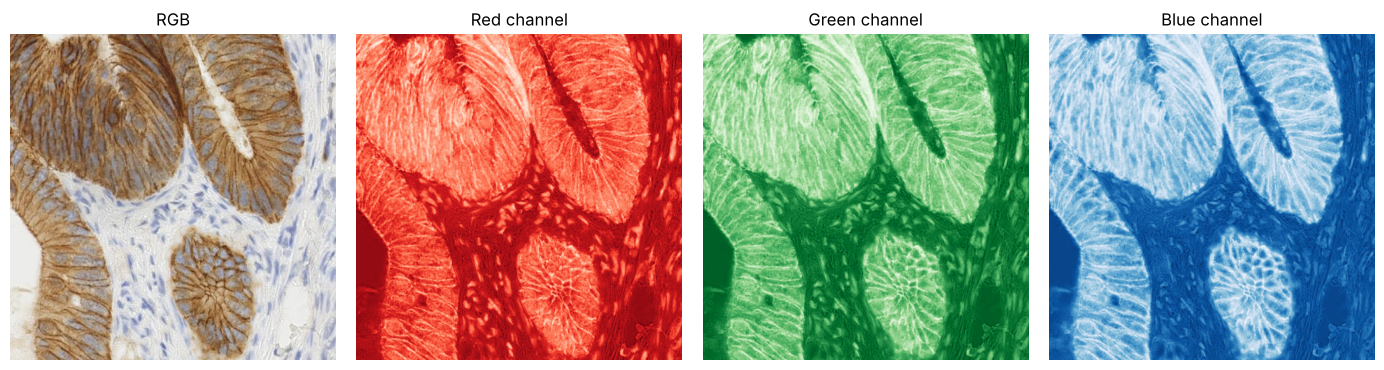

In [2]:
# Example 3.1: A digital image from a computer's perspective — a matrix of numbers
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color
 
rgb = data.immunohistochemistry()          # pathology slide image (IHC staining)
gray = color.rgb2gray(rgb)                 # convert to grayscale, values in [0, 1]
 
print("RGB image shape :", rgb.shape, "| dtype:", rgb.dtype)
print("Gray image shape:", gray.shape)
print("Pixel (100,100) RGB value:", rgb[100, 100])
print("Top-left 4x4 gray block (x255):\n", (gray[:4, :4] * 255).astype(int))
 
fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
ax[0].imshow(rgb); ax[0].set_title("RGB")
for i, (ch, cm) in enumerate([("Red", "Reds"), ("Green", "Greens"), ("Blue", "Blues")]):
    ax[i + 1].imshow(rgb[:, :, i], cmap=cm); ax[i + 1].set_title(f"{ch} channel")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("fig3_1.png", dpi=300)

## Example 3.2: Automatic counting of cell nuclei with a classic image processing pipeline

Script version: `example_3_2.py`

/tmp/ipykernel_246/1929874966.py:16: FutureWarning: `binary_opening` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.opening` instead.
  mask = morphology.binary_opening(mask, morphology.disk(2))  # 3) erosion + dilation


Number of detected nuclei: 130
Mean nucleus area (pixels): 317.5
Largest / smallest area: 6747.0 / 61.0


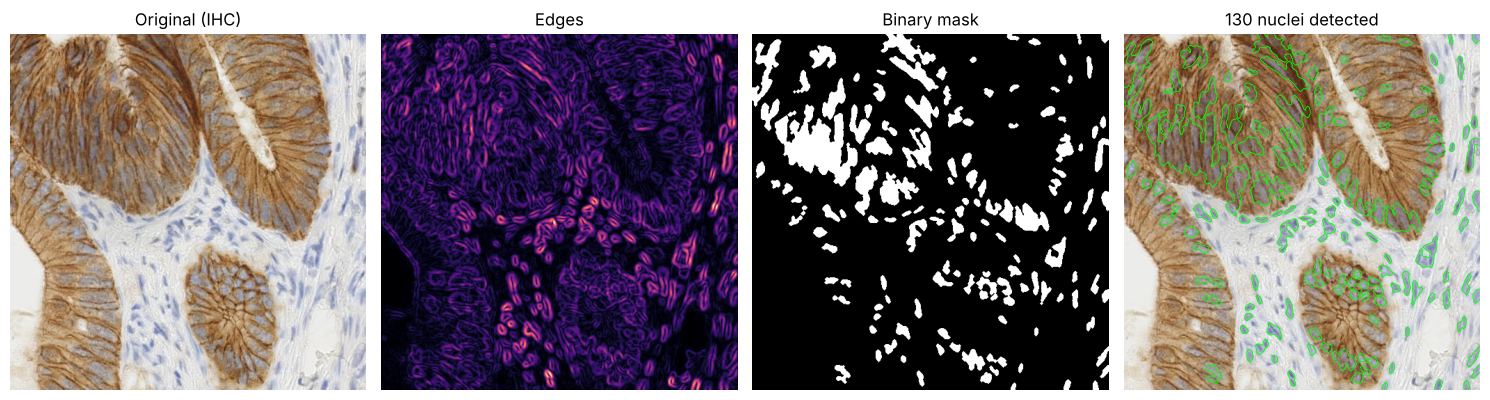

In [3]:
# Example 3.2: Automatic cell counting with a classic image processing pipeline
# Gray -> Edge -> Dilate -> Fill holes -> Remove small objects -> Label
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import data, color, filters, morphology, measure
 
rgb = data.immunohistochemistry()
# Color deconvolution: separate the hematoxylin stain (cell nuclei)
hed = color.rgb2hed(rgb)
nuclei = hed[:, :, 0]
 
smooth = filters.gaussian(nuclei, sigma=1.5)                # 0) denoise
edges = filters.sobel(smooth)                               # 1) edge image
mask = smooth > np.percentile(smooth, 82)                   # 2) keep darkest-stained pixels
mask = morphology.binary_opening(mask, morphology.disk(2))  # 3) erosion + dilation
mask = ndi.binary_fill_holes(mask)                          # 4) fill holes
mask = morphology.remove_small_objects(mask, max_size=60)   # 5) remove small objects
labels = measure.label(mask)                                # 6) label connected parts
props = measure.regionprops(labels)
 
areas = [p.area for p in props]
print("Number of detected nuclei:", labels.max())
print("Mean nucleus area (pixels):", round(np.mean(areas), 1))
print("Largest / smallest area:", max(areas), "/", min(areas))
 
fig, ax = plt.subplots(1, 4, figsize=(15, 4))
ax[0].imshow(rgb); ax[0].set_title("Original (IHC)")
ax[1].imshow(edges, cmap="magma"); ax[1].set_title("Edges")
ax[2].imshow(mask, cmap="gray"); ax[2].set_title("Binary mask")
ax[3].imshow(rgb); ax[3].contour(mask, [0.5], colors="lime", linewidths=0.6)
ax[3].set_title(f"{labels.max()} nuclei detected")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("fig3_3.png", dpi=300)

## Example 3.3: Extracting HOG features

Script version: `example_3_3.py`

Image size: (256, 256)
HOG feature vector length: 8100


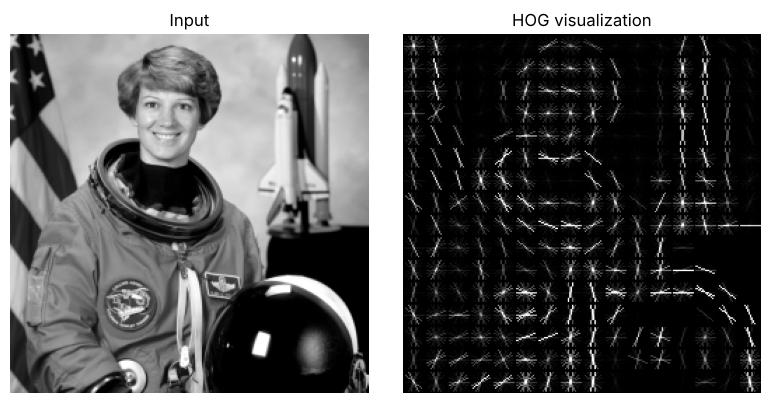

In [4]:
# Example 3.3: Extracting HOG features (histogram of oriented gradients)
import matplotlib.pyplot as plt
from skimage import data, color, exposure
from skimage.feature import hog
from skimage.transform import resize
 
img = resize(color.rgb2gray(data.astronaut()), (256, 256))
features, hog_img = hog(img, orientations=9, pixels_per_cell=(16, 16),
                        cells_per_block=(2, 2), visualize=True)
print("Image size:", img.shape)
print("HOG feature vector length:", features.shape[0])
 
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("Input")
ax[1].imshow(exposure.rescale_intensity(hog_img, in_range=(0, 0.08)), cmap="gray")
ax[1].set_title("HOG visualization")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("fig3_4.png", dpi=300)

## Example 3.4: Manual implementation of 2D convolution

Script version: `example_3_4.py`

In [5]:
# Example 3.4: Manual convolution on a 5×5 binary image (the slide example)
import numpy as np
 
def conv2d(img, kernel, stride=1, padding=0):
    if padding:
        img = np.pad(img, padding)                     # zero padding
    k = kernel.shape[0]
    out = (img.shape[0] - k) // stride + 1             # output size
    fmap = np.zeros((out, out))
    for i in range(out):
        for j in range(out):
            patch = img[i*stride:i*stride+k, j*stride:j*stride+k]
            fmap[i, j] = np.sum(patch * kernel)        # element-wise product, then sum
    return fmap
 
image = np.array([[1, 1, 1, 0, 0],
                  [0, 1, 1, 1, 0],
                  [0, 0, 1, 1, 1],
                  [0, 0, 1, 1, 0],
                  [0, 1, 1, 0, 0]])
kernel = np.array([[1, 0, 1],
                   [0, 1, 0],
                   [1, 0, 1]])
print("Convolved feature:\n", conv2d(image, kernel).astype(int))

Convolved feature:
 [[4 3 4]
 [2 4 3]
 [2 3 4]]


## Example 3.5: Convolution with a sharpening kernel and zero padding

Script version: `example_3_5.py`

In [6]:
# Example 3.5: Convolution with a sharpening kernel and zero padding (the slide example)
import numpy as np
from scipy.signal import correlate2d
 
img = np.array([[ 60, 113,  56, 139,  85],
                [ 73, 121,  54,  84, 128],
                [131,  99,  70, 129, 127],
                [ 80,  57, 115,  69, 134],
                [104, 126, 123,  95, 130]])
kernel = np.array([[ 0, -1,  0],
                   [-1,  5, -1],
                   [ 0, -1,  0]])
 
# mode="same" + fill=0  == zero padding of 1 pixel -> output is also 5x5
out = correlate2d(img, kernel, mode="same", boundary="fill", fillvalue=0)
print("Output feature map (5x5):\n", out)

Output feature map (5x5):
 [[ 114  328  -26  470  158]
 [  53  266  -61  -30  344]
 [ 403  116  -47  295  244]
 [ 108 -135  256 -128  344]
 [ 314  346  279  153  421]]


## Example 3.6: The effect of different kernels on a retinal image

Script version: `example_3_6.py`

Blur (mean 5x5)    kernel (5, 5) -> output range [0.25, 0.80]
Sharpen            kernel (3, 3) -> output range [0.19, 0.82]
Edge (Sobel-x)     kernel (3, 3) -> output range [-0.50, 0.39]
Edge (Laplacian)   kernel (3, 3) -> output range [-0.17, 0.16]


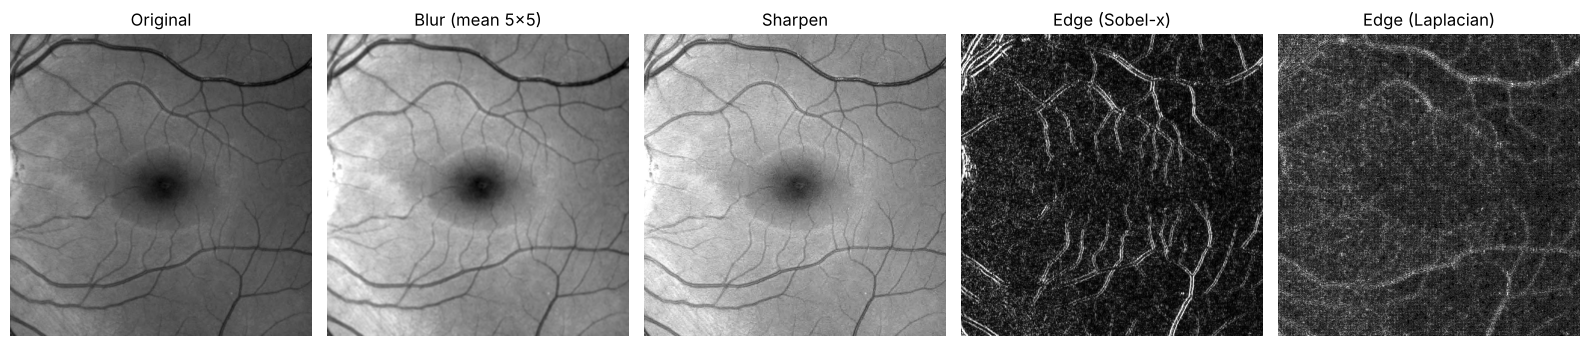

In [7]:
# Example 3.6: The effect of different convolution filters on a real image
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve
from skimage import data, color
 
img = color.rgb2gray(data.retina())[300:1100, 300:1100]     # fundus (retina) image
kernels = {
    "Blur (mean 5x5)": np.ones((5, 5)) / 25,
    "Sharpen": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "Edge (Sobel-x)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "Edge (Laplacian)": np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]]),
}
fig, ax = plt.subplots(1, 5, figsize=(16, 3.6))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("Original")
for a, (name, k) in zip(ax[1:], kernels.items()):
    out = convolve(img, k)
    shown = np.abs(out) if "Edge" in name else out
    a.imshow(shown, cmap="gray", vmax=np.percentile(shown, 99.5)); a.set_title(name)
    print(f"{name:<18} kernel {k.shape} -> output range [{out.min():.2f}, {out.max():.2f}]")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("fig3_2.png", dpi=300)

## Example 3.7: Three types of pooling on the slide matrix

Script version: `example_3_7.py`

In [8]:
# Example 3.7: Types of pooling — Max, Average, and Sum (the slide example)
import numpy as np
 
def pool2d(x, size=2, mode="max"):
    h, w = x.shape[0] // size, x.shape[1] // size
    blocks = x[:h*size, :w*size].reshape(h, size, w, size).swapaxes(1, 2)
    if mode == "max": return blocks.max(axis=(2, 3))
    if mode == "avg": return blocks.mean(axis=(2, 3))
    if mode == "sum": return blocks.sum(axis=(2, 3))
 
x = np.array([[ 2,  3, 2, 0],
              [ 5, -2, 2, 8],
              [-1, -6, 7, 3],
              [-4, -5, 4, 2]])
for mode in ["max", "avg", "sum"]:
    print(f"{mode.upper()} pooling:\n", pool2d(x, 2, mode))

MAX pooling:
 [[ 5  8]
 [-1  7]]
AVG pooling:
 [[ 2.  3.]
 [-4.  4.]]
SUM pooling:
 [[  8  12]
 [-16  16]]


## Example 3.8: Tracing the dimensions and number of parameters of VGG-16

Script version: `example_3_8.py`

In [9]:
# Example 3.8: Tracing the dimensions and number of parameters of VGG-16 without any deep learning library
cfg = [64, 64, "P", 128, 128, "P", 256, 256, 256, "P",
       512, 512, 512, "P", 512, 512, 512, "P"]
 
size, ch, total = 224, 3, 0
print(f"{'layer':<14}{'output shape':<18}{'params':>12}")
for i, v in enumerate(cfg):
    if v == "P":
        size //= 2
        print(f"{'maxpool/2':<14}{f'{size}x{size}x{ch}':<18}{0:>12,}")
    else:
        params = 3 * 3 * ch * v + v          # weights + biases of a 3x3 conv
        ch, total = v, total + params
        print(f"{'conv3x3-' + str(v):<14}{f'{size}x{size}x{ch}':<18}{params:>12,}")
 
n_in = size * size * ch                       # flatten: 7*7*512
for units in (4096, 4096, 1000):
    params = n_in * units + units
    total += params
    print(f"{'fc-' + str(units):<14}{str(units):<18}{params:>12,}")
    n_in = units
print(f"Total parameters: {total:,}")

layer         output shape            params
conv3x3-64    224x224x64               1,792
conv3x3-64    224x224x64              36,928
maxpool/2     112x112x64                   0
conv3x3-128   112x112x128             73,856
conv3x3-128   112x112x128            147,584
maxpool/2     56x56x128                    0
conv3x3-256   56x56x256              295,168
conv3x3-256   56x56x256              590,080
conv3x3-256   56x56x256              590,080
maxpool/2     28x28x256                    0
conv3x3-512   28x28x512            1,180,160
conv3x3-512   28x28x512            2,359,808
conv3x3-512   28x28x512            2,359,808
maxpool/2     14x14x512                    0
conv3x3-512   14x14x512            2,359,808
conv3x3-512   14x14x512            2,359,808
conv3x3-512   14x14x512            2,359,808
maxpool/2     7x7x512                      0
fc-4096       4096               102,764,544
fc-4096       4096                16,781,312
fc-1000       1000                 4,097,000
Total para

## Example 3.9: Extracting axial, coronal, and sagittal slices from a 3D volume

Script version: `example_3_9.py`

Volume shape (z, y, x): (128, 128, 128)
Number of axial slices: 128


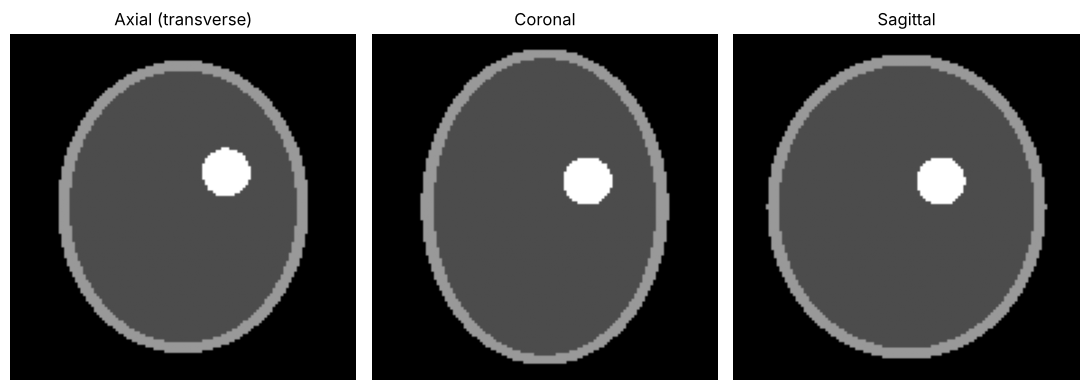

In [10]:
# Example 3.9: Anatomical slices — axial, coronal, and sagittal from a 3D volume
import numpy as np
import matplotlib.pyplot as plt
 
n = 128
z, y, x = np.mgrid[-1:1:n*1j, -1:1:n*1j, -1:1:n*1j]
vol = np.zeros((n, n, n))
vol[(x**2 / 0.55 + y**2 / 0.75 + z**2 / 0.9) < 1] = 0.6        # "head"
vol[(x**2 / 0.45 + y**2 / 0.65 + z**2 / 0.8) < 1] = 0.3        # "brain"
vol[((x - 0.25)**2 + (y - 0.2)**2 + (z - 0.15)**2) < 0.02] = 1.0  # a lesion
 
print("Volume shape (z, y, x):", vol.shape)
print("Number of axial slices:", vol.shape[0])
slices = {"Axial (transverse)": vol[n // 2 + 10, :, :],
          "Coronal": vol[:, n // 2 + 13, :],
          "Sagittal": vol[:, :, n // 2 + 16]}
fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
for a, (name, s) in zip(ax, slices.items()):
    a.imshow(s, cmap="gray", origin="lower"); a.set_title(name); a.axis("off")
plt.tight_layout(); plt.savefig("fig3_7.png", dpi=300)

## Example 3.10: Simulating radiography with the Beer-Lambert law

Script version: `example_3_10.py`

Attenuation coefficients used (soft, air, bone): 0.2 0.02 0.5
Detector image shape: (160, 160)
Transmitted intensity range: [0.029, 1.000]


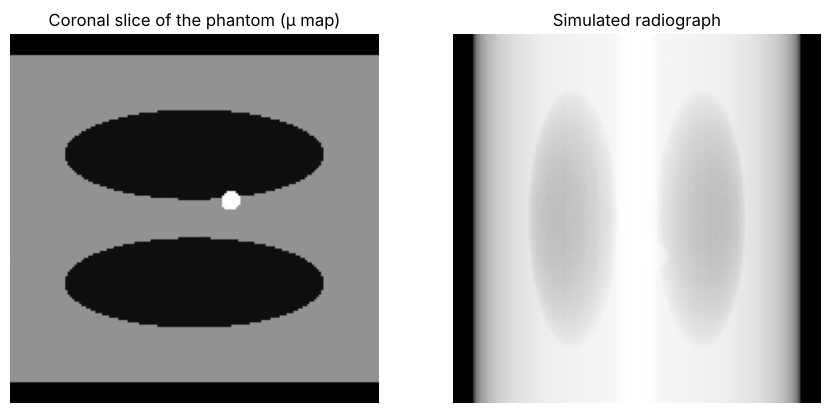

In [11]:
# Example 3.10: Simulating X-ray imaging with the Beer-Lambert law
# I = I0 * exp(-∫ μ dx)  — each tissue absorbs X-rays differently
import numpy as np
import matplotlib.pyplot as plt
 
# a simple 3D "phantom": soft-tissue body, two lungs (air) and a spine (bone)
n = 160
z, y, x = np.mgrid[-1:1:n*1j, -1:1:n*1j, -1:1:n*1j]
mu = np.zeros((n, n, n))
mu[(x**2 / 0.8 + y**2 / 0.5) < 1] = 0.20                       # soft tissue
for cx in (-0.35, 0.35):
    mu[((x - cx)**2 / 0.06 + y**2 / 0.12 + z**2 / 0.5) < 1] = 0.02  # lungs (air)
mu[((x)**2 + (y + 0.45)**2) < 0.012] = 0.50                    # spine (bone)
mu[((x - 0.1)**2 + (y + 0.05)**2 + (z - 0.2)**2) < 0.006] = 0.35  # a nodule
 
I0, dx = 1.0, 2.0 / n * 10
projection = I0 * np.exp(-mu.sum(axis=1) * dx)   # X-rays travel along the y axis
 
print("Attenuation coefficients used (soft, air, bone):", 0.20, 0.02, 0.50)
print("Detector image shape:", projection.shape)
print("Transmitted intensity range: [%.3f, %.3f]" % (projection.min(), projection.max()))
 
fig, ax = plt.subplots(1, 2, figsize=(9, 4.2))
ax[0].imshow(mu[:, n // 2, :].T, cmap="gray", origin="lower")
ax[0].set_title("Coronal slice of the phantom (μ map)")
ax[1].imshow(1 - projection, cmap="gray")   # radiograph convention: dense = bright
ax[1].set_title("Simulated radiograph")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("fig3_5.png", dpi=300)

## Example 3.11: A complete CT simulation — from projection to reconstruction

Script version: `example_3_11.py`

 18 angles -> sinogram (200, 18), reconstruction RMSE = 0.1459
180 angles -> sinogram (200, 180), reconstruction RMSE = 0.0253


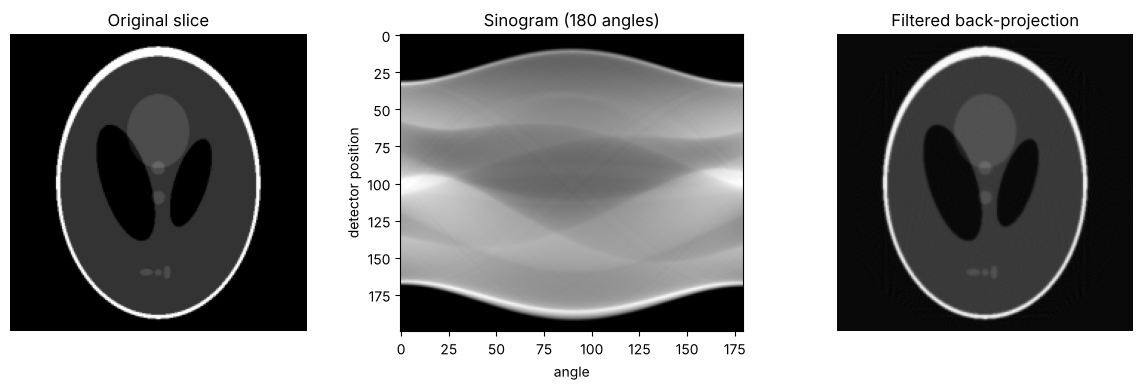

In [12]:
# Example 3.11: CT scanning — from projection images to a reconstructed slice
import numpy as np
import matplotlib.pyplot as plt
from skimage.data import shepp_logan_phantom
from skimage.transform import radon, iradon, rescale
 
phantom = rescale(shepp_logan_phantom(), 0.5)       # 200x200 head phantom
for n_angles in (18, 180):
    theta = np.linspace(0, 180, n_angles, endpoint=False)
    sino = radon(phantom, theta=theta)               # projections from many angles
    recon = iradon(sino, theta=theta, filter_name="ramp")
    err = np.sqrt(np.mean((recon - phantom) ** 2))
    print(f"{n_angles:>3} angles -> sinogram {sino.shape}, reconstruction RMSE = {err:.4f}")
 
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(phantom, cmap="gray"); ax[0].set_title("Original slice")
ax[1].imshow(sino, cmap="gray", aspect="auto"); ax[1].set_title("Sinogram (180 angles)")
ax[1].set_xlabel("angle"); ax[1].set_ylabel("detector position")
ax[2].imshow(recon, cmap="gray"); ax[2].set_title("Filtered back-projection")
ax[0].axis("off"); ax[2].axis("off")
plt.tight_layout(); plt.savefig("fig3_6.png", dpi=300)

## Example 3.12: Computing Hounsfield units and windowing

Script version: `example_3_12.py`

air          mu=0.0   -> HU = -1000.0
lung         mu=0.05  -> HU =  -736.8
fat          mu=0.17  -> HU =  -105.3
water        mu=0.19  -> HU =     0.0
soft tissue  mu=0.2   -> HU =    52.6
bone         mu=0.38  -> HU =  1000.0


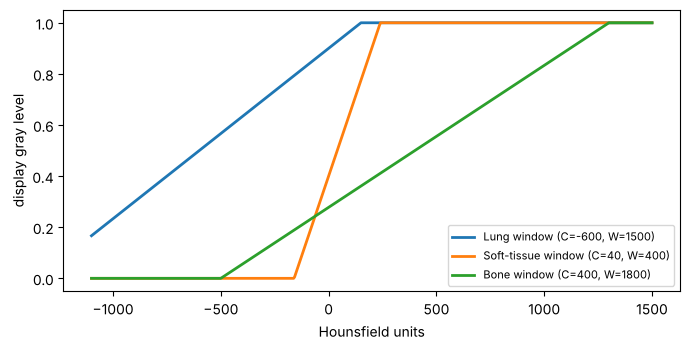

In [13]:
# Example 3.12: Hounsfield units and windowing in CT images
import numpy as np
import matplotlib.pyplot as plt
 
def mu_to_hu(mu, mu_water=0.19, mu_air=0.0):
    return 1000 * (mu - mu_water) / (mu_water - mu_air)
 
def window(hu, center, width):
    lo, hi = center - width / 2, center + width / 2
    return np.clip((hu - lo) / (hi - lo), 0, 1)
 
for tissue, mu in [("air", 0.0), ("lung", 0.05), ("fat", 0.17), ("water", 0.19),
                   ("soft tissue", 0.20), ("bone", 0.38)]:
    print(f"{tissue:<12} mu={mu:<5} -> HU = {mu_to_hu(mu):7.1f}")
 
hu = np.linspace(-1100, 1500, 600)
plt.figure(figsize=(7, 3.6))
for name, c, w in [("Lung window", -600, 1500), ("Soft-tissue window", 40, 400), ("Bone window", 400, 1800)]:
    plt.plot(hu, window(hu, c, w), lw=2, label=f"{name} (C={c}, W={w})")
plt.xlabel("Hounsfield units"); plt.ylabel("display gray level"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig3_8.png", dpi=300)